# Yu et al. 2024: a 2D ResNet34 with hard and soft voting

## 1. Paper summary and reference

S. Yu, X. Liang, S. Zhao, Y. Xie, Q. Sun, *Three-dimensional automated breast ultrasound (ABUS) tumor classification using a 2D-input network: soft voting or hard voting?*, Applied Sciences 14(24):11611 (2024), [doi:10.3390/app142411611](https://doi.org/10.3390/app142411611).

A 2D network classifies each tumor slice, and the slices are combined per volume. Hard voting (Eq. 3) takes the majority of slices. Soft voting (Eq. 1) weights each slice's probability by its tumor voxels. We implement Sections 2.2, 2.4 and 2.5 for ResNet34, the paper's best network.

In [1]:
import sys
sys.path.insert(0, "..")
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from abus_classification.papers.yu2024 import YuResNet
from abus_classification.papers.yu2024.pipeline import votes
from abus_classification.protocol import auc_ci

RESULTS = Path("../results/yu2024")
table = pd.read_csv(RESULTS / "yu2024_results.csv", index_col=0)
slices = np.load(RESULTS / "yu2024_test_slices.npz")
case, voxels, y = slices["case"], slices["voxels"], slices["y"]
MODES = ["resnet34", "resnet34_crop", "resnet34_scratch"]
COLORS = dict(resnet34="#2a78d6", resnet34_crop="#4a3aa7", resnet34_scratch="#898781")

## 2. Implementation details

| Item | Paper | Ours | Status |
|---|---|---|---|
| Samples | Slices with tumor, 2028 on Train (Section 2.4) | Axis 2 slices with tumor, **3170** on Train | **Differs**, unexplained (Section 7) |
| Network | ResNet34 (also MedViT, HiFuse, MedMamba, 3D networks) | ResNet34 only | **Deviation**: it is the paper's best |
| Epochs | 100 | 100, last epoch used | Follows |
| Soft voting | Eq. 1, voxel-weighted mean | Same, `votes` | Follows |
| Hard voting | Eq. 3, majority of slices | Share of malignant slices; a tie counts as malignant | Tie is **assumed** |
| Weights | Tumor voxels per slice | From ground-truth masks | Follows; a real system needs a segmentation first |
| Evaluation | Five-fold CV on Train (100) | Train + Validation to Test (70), 3 seeds; plus five-fold CV on Train, one seed | **Deviation**, with the paper's protocol as well |
| Input | Whole slices in Fig. 2; "smaller slices" in the discussion | Whole slices; `resnet34_crop` uses the slice's lesion box | **Assumed**, both run |
| Pretraining | Not given | ImageNet; `resnet34_scratch` without | **Assumed**, both run |
| Size | Not given | 224 x 224, ignoring aspect ratio | **Assumed** |
| Optimizer, loss | Not given | Adam, lr 1e-4, batch 32, cross-entropy | **Assumed** |
| Augmentation | Not given | None | **Assumed** |

## 3. Verification of the implementation

Unit tests are in `test/papers_tests/test_yu2024.py`: slice extraction and voxel counts, hand-computed votes, parameter count and an overfit run with a tiny stand-in network.

In [2]:
net = YuResNet(pretrained=False).eval()
print("output", tuple(net(torch.zeros(2, 1, 224, 224)).shape), "parameters", f"{sum(p.numel() for p in net.parameters()):,}")
_, hard, soft = votes(np.array([0.9, 0.2, 0.2]), np.array([800, 100, 100]), np.zeros(3, int))
print("one large malignant slice, two small benign: hard", round(hard[0], 3), "soft", round(soft[0], 3), "(by hand: 1/3 and 0.76)")

output (2, 2) parameters 21,285,698
one large malignant slice, two small benign: hard 0.333 soft 0.76 (by hand: 1/3 and 0.76)


**Stored predictions reproduce the Kaggle table.** The slice map comes from the local Test masks, and the probabilities from the kernel.

In [3]:
rows = []
for mode in MODES:
    for seed in range(3):
        p = np.load(RESULTS / f"yu2024_{mode}_seed{seed}.npz")["prob"]
        _, hard, soft = votes(p, voxels, case)
        rows.append(dict(run=f"{mode} seed {seed}", soft=roc_auc_score(y, soft), soft_table=table.loc[f"{mode} soft seed {seed}", "AUC"],
                         hard=roc_auc_score(y, hard), hard_table=table.loc[f"{mode} hard seed {seed}", "AUC"]))
check = pd.DataFrame(rows).set_index("run").round(4)
assert np.allclose(check.soft, check.soft_table, atol=2e-4) and np.allclose(check.hard, check.hard_table, atol=2e-4)
check

,soft,soft_table,hard,hard_table
run,,,,
resnet34 seed 0,0.7250,0.7250,0.7062,0.7062
resnet34 seed 1,0.7900,0.7900,0.7712,0.7712
resnet34 seed 2,0.7208,0.7208,0.7067,0.7067
resnet34_crop seed 0,0.8175,0.8175,0.7971,0.7971
resnet34_crop seed 1,0.8125,0.8125,0.7967,0.7967
resnet34_crop seed 2,0.8075,0.8075,0.7704,0.7704
resnet34_scratch seed 0,0.6950,0.6950,0.6583,0.6583
resnet34_scratch seed 1,0.6017,0.6017,0.5804,0.5804
resnet34_scratch seed 2,0.6983,0.6983,0.7012,0.7012


**The paper's own numbers do not fit together.** With 58 malignant and 42 benign cases, accuracy follows from sensitivity and specificity. Its voting rows also report AUC equal to accuracy.

In [4]:
paper = pd.DataFrame({"ResNet34": (0.865, 0.942, 0.757, 0.936), "ResNet34 + HV": (0.907, 0.990, 0.864, 0.907), "ResNet34 + SV": (0.986, 0.990, 0.963, 0.986),
                      "MedMamba + SV": (0.954, 0.975, 0.943, 0.954)}, index=["ACC", "SEN", "SPE", "AUC"]).T
paper["ACC from SEN, SPE"] = ((58 * paper.SEN + 42 * paper.SPE) / 100).round(3)
paper

,ACC,SEN,SPE,AUC,"ACC from SEN, SPE"
ResNet34,0.865,0.942,0.757,0.936,0.864
ResNet34 + HV,0.907,0.990,0.864,0.907,0.937
ResNet34 + SV,0.986,0.990,0.963,0.986,0.979
MedMamba + SV,0.954,0.975,0.943,0.954,0.962


Fold averages can shift this a little, since folds differ in class balance, but the 0.03 gap for hard voting is large. No code is published to settle it.

**Fast training accuracy.** Training accuracy passes 99% at epoch 2 on whole slices and about epoch 10 on crops. Test AUC is well above chance, so the labels are intact. The likely cause is memorising volumes: a volume's slices look alike and share a label. That is a hypothesis, and a label-shuffling run has not tested it.

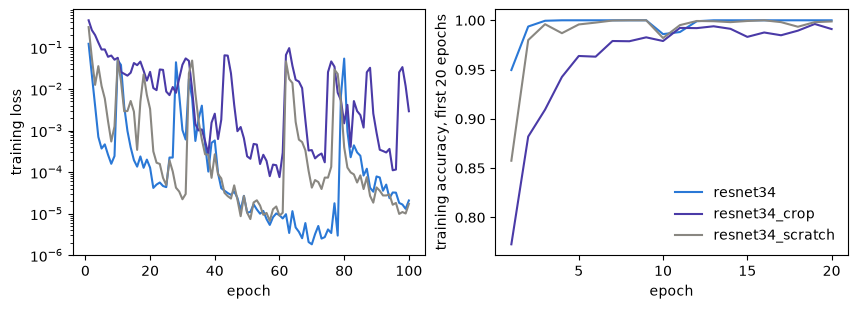

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for mode in MODES:
    h = pd.read_csv(RESULTS / f"yu2024_{mode}_seed0_history.csv")
    ax[0].plot(h.epoch, h.loss, color=COLORS[mode], label=mode); ax[1].plot(h.epoch.head(20), h.acc.head(20), color=COLORS[mode], label=mode)
ax[0].set(xlabel="epoch", ylabel="training loss", yscale="log"); ax[1].set(xlabel="epoch", ylabel="training accuracy, first 20 epochs"); ax[1].legend(frameon=False)
plt.show()

## 4. Images

**Method**, redrawn from the paper's Fig. 2: tumor slices, then ResNet34 per slice, then voting weighted by tumor voxels. **Our outputs**: the training curves above, and ROC curves and slices per volume below.

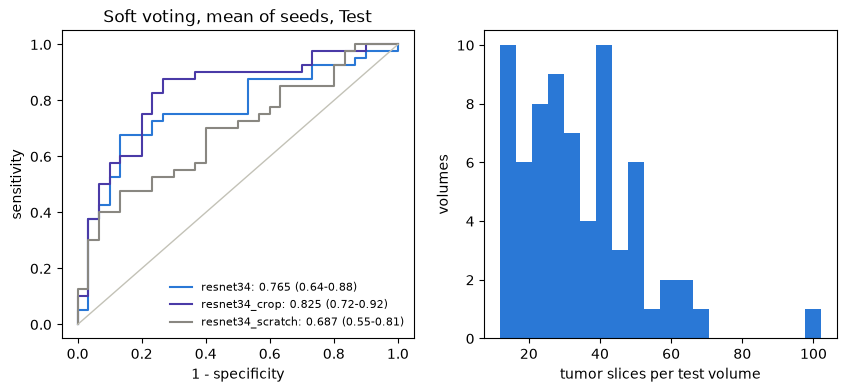

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for mode in MODES:
    mean = np.mean([votes(np.load(RESULTS / f"yu2024_{mode}_seed{s}.npz")["prob"], voxels, case)[2] for s in range(3)], 0)
    fpr, tpr, _ = roc_curve(y, mean)
    low, high = auc_ci(y, mean)
    ax[0].plot(fpr, tpr, color=COLORS[mode], label=f"{mode}: {roc_auc_score(y, mean):.3f} ({low:.2f}-{high:.2f})")
ax[0].plot([0, 1], [0, 1], color="#c3c2b7", lw=1); ax[0].set(xlabel="1 - specificity", ylabel="sensitivity", title="Soft voting, mean of seeds, Test"); ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(np.bincount(case), bins=20, color="#2a78d6"); ax[1].set(xlabel="tumor slices per test volume", ylabel="volumes")
plt.show()

## 5. Tables

The paper's numbers are five-fold CV on Train. Compare them with our CV rows, which use the same split sizes. The paper reports no seed variance. Its AUC for voting looks computed from labels, so `Balanced`, (sensitivity + specificity) / 2, is the closest match to those rows, and `AUC` here always comes from continuous scores.

In [7]:
cols = ["AUC", "Balanced", "Acc", "Sens", "Spec", "Score"]
held = []
for mode in MODES:
    for kind in ("slices", "hard", "soft"):
        t = table.loc[[f"{mode} {kind} seed {s}" for s in range(3)], cols]
        held.append(pd.Series({**t.mean().round(3).to_dict(), "AUC seed sd": round(t.AUC.std(), 3)}, name=f"{mode} {kind}"))
display(pd.DataFrame(held))
cv = table.loc[[i for i in table.index if i.endswith(" cv")], cols].round(3)
pp = pd.DataFrame({"paper ResNet34": (0.936, 0.865, 0.942, 0.757), "paper + HV": (0.907, 0.907, 0.990, 0.864), "paper + SV": (0.986, 0.986, 0.990, 0.963)}, index=["AUC", "Acc", "Sens", "Spec"]).T
display(cv); display(pp)
diff = pd.Series({"slices": cv.loc["resnet34_crop slices cv", "AUC"] - 0.936, "hard": cv.loc["resnet34_crop hard cv", "AUC"] - 0.907, "soft": cv.loc["resnet34_crop soft cv", "AUC"] - 0.986}, name="our best CV AUC minus paper").round(3)
diff

,AUC,Balanced,Acc,Sens,Spec,Score,AUC seed sd
resnet34 slices,0.749,0.672,0.698,0.754,0.590,0.723,0.024
resnet34 hard,0.728,0.654,0.671,0.775,0.533,0.700,0.037
resnet34 soft,0.745,0.679,0.695,0.792,0.567,0.720,0.039
resnet34_crop slices,0.719,0.616,0.685,0.832,0.401,0.702,0.010
resnet34_crop hard,0.788,0.647,0.686,0.917,0.378,0.737,0.015
resnet34_crop soft,0.812,0.662,0.700,0.925,0.400,0.756,0.005
resnet34_scratch slices,0.689,0.628,0.668,0.754,0.502,0.679,0.029
resnet34_scratch hard,0.647,0.614,0.638,0.783,0.444,0.642,0.061
resnet34_scratch soft,0.665,0.597,0.624,0.783,0.411,0.644,0.055


,AUC,Balanced,Acc,Sens,Spec,Score
resnet34 slices cv,0.695,0.648,0.672,0.716,0.579,0.684
resnet34 hard cv,0.705,0.692,0.700,0.742,0.642,0.703
resnet34 soft cv,0.709,0.684,0.690,0.726,0.642,0.699
resnet34_crop slices cv,0.741,0.668,0.713,0.801,0.536,0.727
resnet34_crop hard cv,0.828,0.728,0.750,0.880,0.575,0.789
resnet34_crop soft cv,0.846,0.760,0.780,0.897,0.622,0.813


,AUC,Acc,Sens,Spec
paper ResNet34,0.936,0.865,0.942,0.757
paper + HV,0.907,0.907,0.990,0.864
paper + SV,0.986,0.986,0.990,0.963


slices   -0.195
hard     -0.079
soft     -0.140
Name: our best CV AUC minus paper, dtype: float64

The paper's ablations are other networks, which we did not run. Our variants are in the first table.

## 6. Protocol

- **Split**: fit on Train + Validation (130 volumes), report on the official Test split (70), split by volume. Second evaluation: the paper's five-fold CV on Train (one seed), whole slices and crops.
- **Positive class**: malignant.
- **Seeds**: 3, with AUC bootstrap CI.
- **Re-run**: `python -m abus_classification.papers.yu2024`, or push `kaggle/yu2024/` on the `mralinp` account (private kernel `yu2024-voting`, GPU, about 10 h for all 19 trainings). Finished runs are loaded, not trained again.
- **Results**: `results/yu2024/`: slice probabilities, histories and the results table. `yu2024_test_slices.npz` holds the test slice map, rebuilt from the Test masks.

## 7. Open issues

- **The paper's result does not reproduce.** Our best CV soft voting (crops) falls well short of its 0.986, even on its own protocol. Its internal inconsistencies (Section 3) make the target itself uncertain.
- **Slice count.** We find 3170 tumor slices on Train, the paper 2028. Hypothesis: it filtered small slices or subsampled, which it does not state.
- **Overfitting.** Training reaches about 100% accuracy, with no augmentation by our assumption. Hypothesis: augmentation or early stopping would raise test AUC. Not tested.
- **Crops beat whole slices** in our runs, though confidence intervals overlap. The paper does not say which it used.
- **Soft vs hard voting.** Soft voting's AUC gain over hard voting is small here, with no paired test yet (planned for the unified comparison).